# DSum vs Bias

Reads one triggered-DSUM csv per bias folder (`<parent>/25V/`, `24.5V/`, ...), reduces every run for every PDC found, and saves eight PNGs (plus a summary csv per PDC) directly in the parent folder. Every figure is a grid with one panel per PDC (two columns, filled top-left, top-right, bottom-left, bottom-right):

In [155]:
from pathlib import Path

DATA_ROOT = Path("~/Desktop/UCSDPDCv2/data").expanduser()
PARENT_GLOB = "WorkingBoard_H63/DSum_RT/2.5V_20ns_LED/350nsHold"      # must match exactly one folder inside DATA_ROOT
FILE_GLOB = "*.csv"                     # the DSUM csv inside each bias folder
DELIMITER = ";"

BIN_NS = 10                             # None -> sys_clk_period_ns from the run's config yaml (fallback 10)
BASELINE_BINS = 20                      # baseline = mean of the first this-many bins of each frame (must end before the pulse)

# Summary figures
N_CHUNKS = 10                           # frame chunks used for the Fano error bar

# Waveform figures
NORMALIZE_BY = "area"                   # normalized figure: divide each trace by its pulse "area" or its "peak" bin
PLOT2_XLIM_US = None                    # None = full frame; e.g. (0.1, 0.5) zooms every waveform panel to that range in us

In [156]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import yaml
except ImportError:
    yaml = None

FALLBACK_NUM_SPADS = 4096               # used only if a run's config yaml has no run.n_spad
PULSE_SIGMA = 3                         # pulse window = contiguous bins above this many noise sigma
BIAS_RE = re.compile(r"^\s*(\d+(?:[._p]\d+)?)\s*V", re.I)


def find_parent(root, pattern):
    """The single folder in root matching pattern."""
    hits = sorted(p for p in root.glob(pattern) if p.is_dir())
    if len(hits) != 1:
        raise RuntimeError(f"{pattern!r} must match exactly one folder in {root}; found {[h.name for h in hits]}")
    return hits[0]


def find_bias_dirs(parent):
    """{bias_V: folder} for subfolders named like 25V, 24.5V, 21p5V; highest bias first."""
    out = {}
    for d in sorted(parent.iterdir()):
        m = BIAS_RE.match(d.name)
        if not (d.is_dir() and m):
            continue
        v = float(re.sub(r"[_p]", ".", m.group(1)))
        if v in out:
            warnings.warn(f"duplicate bias {v:g} V: ignoring {d.name}")
            continue
        out[v] = d
    return dict(sorted(out.items(), reverse=True))


def pick_csv(folder):
    hits = sorted(folder.glob(FILE_GLOB))
    if not hits:
        warnings.warn(f"no {FILE_GLOB} in {folder.name}, skipping")
        return None
    if len(hits) > 1:
        warnings.warn(f"{len(hits)} files match {FILE_GLOB} in {folder.name}; using {hits[-1].name}")
    return hits[-1]


def dig(d, *keys):
    for k in keys:
        if not isinstance(d, dict) or k not in d:
            return None
        d = d[k]
    return d


def read_config(csv_path):
    f = csv_path.with_name(csv_path.stem + "_config.yaml")
    if not f.exists():
        return {}
    txt = f.read_text()

    def get(key):
        m = re.search(rf"^\s*{key}:\s*([0-9.]+)\s*$", txt, re.M)
        return float(m.group(1)) if m else None

    n = get("n_spad")
    return {"bin_ns": get("sys_clk_period_ns"), "hold_ns": get("hold_ns"), "num_spads": int(n) if n else None}


def load_frames(csv_path):
    """{pdc: int array (n_frames, n_bins)}; samples the chip did not report (0 counts) are filled with 0."""
    df = pd.read_csv(csv_path, sep=DELIMITER, usecols=["pdcIdx", "frameIdx", "dataIdx", "dsum"])
    out = {}
    for pdc, g in df.groupby("pdcIdx"):
        f, d, v = g["frameIdx"].to_numpy(), g["dataIdx"].to_numpy(), g["dsum"].to_numpy()
        frames, fi = np.unique(f, return_inverse=True)
        M = np.zeros((len(frames), d.max() + 1), dtype=np.int32)
        M[fi, d] = v
        n_zero = M.size - len(g)
        if n_zero > 0:
            print(f"  {csv_path.name} PDC{pdc}: {n_zero} of {M.size} samples not reported, filled with 0 ({100 * n_zero / M.size:.1f}%)")
        out[int(pdc)] = M.astype(np.int16 if M.max() < 32000 else np.int32)
    return out

## Plot Styling

In [157]:
# Shared plot style: this cell is identical in the DSUM and TCR notebooks.
import math
from matplotlib import cm, colors

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "lines.linewidth": 1.2,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.titlesize": 10,
    "axes.formatter.limits": (-3, 4),       # scientific notation outside 1e-3 ... 1e4
    "axes.formatter.use_mathtext": True,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Colour language: blue = bias, warm (yellow -> red) = temperature; darker = higher.
BIAS_CMAP = colors.LinearSegmentedColormap.from_list(
    "bias_blue", ["#9ecae1", "#6baed6", "#2f7fc1", "#0f4c9c", "#0a2f6e", "#05163f"])
TEMP_CMAP = colors.LinearSegmentedColormap.from_list(
    "temp_ylorrd", plt.get_cmap("YlOrRd")(np.linspace(0.30, 1.0, 256)))
HUES = {"bias": (BIAS_CMAP, "Bias (V)"), "temp": (TEMP_CMAP, "Temperature (K)")}


def hue_norm(values):
    lo, hi = float(min(values)), float(max(values))
    return colors.Normalize(lo, hi) if hi > lo else colors.Normalize(lo - 1, hi)   # a single value gets the darkest colour


def hue_color(kind, value, values):
    """Colour of `value` for kind 'bias' or 'temp'; `values` is every value in the figure."""
    return HUES[kind][0](hue_norm(values)(value))


def add_hue_colorbar(fig, axes, kind, values):
    cmap, label = HUES[kind]
    cb = fig.colorbar(cm.ScalarMappable(hue_norm(values), cmap), ax=axes, pad=0.02)
    cb.set_label(label)
    ticks = sorted(set(values))
    if len(ticks) <= 12:
        cb.set_ticks(ticks)
        cb.ax.set_yticklabels([f"{t:g}" for t in ticks])
    cb.ax.tick_params(length=2)


def pdc_grid(n, scale=3.0, sharey=True):
    """Axes for n PDCs: two columns, filled top-left, top-right, bottom-left, bottom-right (one column if n = 1)."""
    ncols = 1 if n == 1 else 2
    nrows = math.ceil(n / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(1.25 * scale * ncols, scale * nrows), squeeze=False,
                            sharex=True, sharey=sharey, layout="constrained")
    flat = list(axs.ravel())
    for ax in flat[n:]:
        ax.set_visible(False)
    flat = flat[:n]
    for i, ax in enumerate(flat):
        if i + ncols >= n:                  # nothing below this panel: keep its x tick labels
            ax.tick_params(labelbottom=True)
    return fig, flat


def label_grid(axs, pdcs, xlabel, ylabel, sharey=True):
    """PDC titles, x label under each column, y label on the left column (every panel if y is not shared)."""
    n = len(axs)
    ncols = 1 if n == 1 else 2
    for i, (ax, pdc) in enumerate(zip(axs, pdcs)):
        ax.set_title(f"PDC {pdc}")
        if i + ncols >= n:
            ax.set_xlabel(xlabel)
        if i % ncols == 0 or not sharey:
            ax.set_ylabel(ylabel)

## Load every bias folder

In [158]:
PARENT = find_parent(DATA_ROOT, PARENT_GLOB)
print("parent:", PARENT)

FRAMES, META = {}, {}
for v, d in find_bias_dirs(PARENT).items():
    csv = pick_csv(d)
    if csv is None:
        continue
    frames, cfg = load_frames(csv), read_config(csv)
    n_spad = cfg.get("num_spads")
    if n_spad is None:
        warnings.warn(f"{v:g} V: run.n_spad not found in the config yaml, using {FALLBACK_NUM_SPADS}")
        n_spad = FALLBACK_NUM_SPADS
    for pdc, M in frames.items():
        FRAMES[(pdc, v)] = M
        META[(pdc, v)] = {
            "file": csv.name,
            "bin_ns": BIN_NS or cfg.get("bin_ns") or 10,
            "hold_ns": cfg.get("hold_ns"),
            "num_spads": int(n_spad),
        }
    print(f"{v:>5g} V  {csv.name}  frames/PDC={ {p: M.shape[0] for p, M in frames.items()} }  num_spads={n_spad}")

if not FRAMES:
    raise RuntimeError("no data loaded; check DATA_ROOT / PARENT_GLOB / FILE_GLOB")
PDC_LIST = sorted({p for p, _ in FRAMES})
num_spads = max(m["num_spads"] for m in META.values())
if len({m["num_spads"] for m in META.values()}) > 1:
    warnings.warn(f"runs report different num_spads; axis labels use {num_spads}")

parent: C:\Users\p6k\Desktop\UCSDPDCv2\data\WorkingBoard_H63\DSum_RT\2.5V_20ns_LED\350nsHold
  20261102_10h35m15_dsum_trigger_H63_NZKF_time_25V_90s.csv PDC0: 3852278 of 3924096 samples not reported, filled with 0 (98.2%)
  20261102_10h35m15_dsum_trigger_H63_NZKF_time_25V_90s.csv PDC1: 3732229 of 3800192 samples not reported, filled with 0 (98.2%)
  20261102_10h35m15_dsum_trigger_H63_NZKF_time_25V_90s.csv PDC2: 3954119 of 4025856 samples not reported, filled with 0 (98.2%)
  20261102_10h35m15_dsum_trigger_H63_NZKF_time_25V_90s.csv PDC3: 3811039 of 3879936 samples not reported, filled with 0 (98.2%)
   25 V  20261102_10h35m15_dsum_trigger_H63_NZKF_time_25V_90s.csv  frames/PDC={0: 30657, 1: 29689, 2: 31452, 3: 30312}  num_spads=4096
  20261102_10h43m15_dsum_trigger_H63_NZKF_time_24V5_90s.csv PDC0: 3733204 of 3801472 samples not reported, filled with 0 (98.2%)
  20261102_10h43m15_dsum_trigger_H63_NZKF_time_24V5_90s.csv PDC1: 3628774 of 3694208 samples not reported, filled with 0 (98.2%)
  

## Reduce each run

In [159]:
def window(center, half, n):
    return np.arange(max(center - half, 0), min(center + half + 1, n))


def find_pulse(M):
    """Pulse bin and half width: contiguous bins around the peak above PULSE_SIGMA x robust noise of the average trace."""
    d = M.mean(axis=0)
    d = d - np.median(d)
    sigma = 1.4826 * np.median(np.abs(d))
    pk = int(np.argmax(d))
    lo = hi = pk
    while lo > 0 and d[lo - 1] > PULSE_SIGMA * sigma:
        lo -= 1
    while hi < len(d) - 1 and d[hi + 1] > PULSE_SIGMA * sigma:
        hi += 1
    return pk, max(pk - lo, hi - pk, 1)


def make_masks(pk, hw, nb):
    """Pulse window, baseline mask (first BASELINE_BINS bins), and a same-width control window far from the pulse."""
    n = min(BASELINE_BINS, pk - hw)
    if n < BASELINE_BINS:
        warnings.warn(f"BASELINE_BINS={BASELINE_BINS} reaches the pulse (starts at bin {pk - hw}); using the first {n} bins")
    if n < 1:
        raise ValueError("no bins before the pulse to use as baseline")
    pw = window(pk, hw, nb)
    base = np.zeros(nb, bool)
    base[:n] = True
    cc = (pk + nb) // 2 if pk < nb / 2 else pk // 2
    return pw, base, window(cc, hw, nb)


def fano(Mb):
    """Var/mean per bin, variance from consecutive-frame differences so slow drift drops out."""
    D = np.diff(Mb.astype(np.float64), axis=0)
    return (D.var(axis=0) / 2).mean() / Mb.mean()


def analyze(M, meta, pk, hw):
    nf, nb = M.shape
    dt = meta["bin_ns"] * 1e-9
    pw, base, cw = make_masks(pk, hw, nb)

    fb = M[:, base].mean(axis=1)
    S = M[:, pw].sum(axis=1) - len(pw) * fb
    C = M[:, cw].sum(axis=1) - len(cw) * fb
    avg = M.mean(axis=0)
    base_level = avg[base].mean()
    area, sigma = S.mean(), C.std(ddof=1)
    area_err = S.std(ddof=1) / np.sqrt(nf)

    chunks = [fano(c) for c in np.array_split(M[:, base], N_CHUNKS)]
    X = M - avg
    psd = (2 * dt / nb) * (np.abs(np.fft.rfft(X, axis=1)) ** 2).mean(axis=0)
    snr_scale = 1 / sigma

    return {
        "n_frames": nf,
        "hold_ns": meta["hold_ns"],
        "baseline": base_level,
        "pulse_area": area,
        "pulse_area_err": area_err,
        "snr": area * snr_scale,
        "snr_err": area_err * snr_scale,
        "sigma_frame": sigma,
        "fano": fano(M[:, base]),
        "fano_err": np.std(chunks, ddof=1) / np.sqrt(N_CHUNKS),
        "bin_ns": meta["bin_ns"],
        "pw": pw,
        "frame_mean": avg.mean(),
        "sig": avg - base_level,
        "psd": psd,
        "freq_MHz": np.fft.rfftfreq(nb, dt) / 1e6,
    }


RES = {}
for pdc in PDC_LIST:
    keys = sorted(k for k in FRAMES if k[0] == pdc)
    ref_v = max(v for _, v in keys)
    pk, hw = find_pulse(FRAMES[(pdc, ref_v)])
    ns = META[(pdc, ref_v)]["bin_ns"]
    print(f"PDC{pdc}: pulse bin {pk} ({pk * ns:g} ns), half width {hw} bins ({2 * hw + 1}-bin window), measured on the {ref_v:g} V run; baseline = bins 0-{min(BASELINE_BINS, pk - hw) - 1}")
    for k in keys:
        RES[k] = analyze(FRAMES[k], META[k], pk, hw)

SCALARS = [
    "n_frames", "hold_ns", "baseline", "pulse_area", "pulse_area_err",
    "snr", "snr_err", "sigma_frame", "fano", "fano_err",
]
rows = {}
for (pdc, v), r in RES.items():
    rows.setdefault(pdc, []).append({"bias": v, **{k: r[k] for k in SCALARS}})
SUMMARY = {p: pd.DataFrame(rs).sort_values("bias").reset_index(drop=True) for p, rs in rows.items()}

for pdc, df in SUMMARY.items():
    df.to_csv(PARENT / f"PDC{pdc}_bias_summary.csv", index=False)
    print(f"\nPDC{pdc}")
    display(df)
print("\nsaving to", PARENT)

PDC0: pulse bin 26 (260 ns), half width 1 bins (3-bin window), measured on the 25 V run; baseline = bins 0-19
PDC1: pulse bin 26 (260 ns), half width 1 bins (3-bin window), measured on the 25 V run; baseline = bins 0-19
PDC2: pulse bin 26 (260 ns), half width 1 bins (3-bin window), measured on the 25 V run; baseline = bins 0-19
PDC3: pulse bin 26 (260 ns), half width 1 bins (3-bin window), measured on the 25 V run; baseline = bins 0-19

PDC0


,bias,n_frames,hold_ns,baseline,pulse_area,pulse_area_err,snr,snr_err,sigma_frame,fano,fano_err
0,21.5,5840,350.0,0.007611,0.021858,0.002938,0.122790,0.016505,0.178011,1.021547,0.007998
1,22.0,21522,350.0,0.009156,0.035492,0.001845,0.187303,0.009738,0.189487,1.091144,0.007711
2,22.5,24157,350.0,0.009701,0.037544,0.001827,0.192121,0.009350,0.195418,1.129127,0.005405
3,23.0,25820,350.0,0.010221,0.040290,0.001844,0.197606,0.009044,0.203893,1.176059,0.011663
4,23.5,27344,350.0,0.010461,0.039894,0.001833,0.189807,0.008720,0.210180,1.203418,0.009901
5,24.0,28830,350.0,0.011126,0.043522,0.001966,0.189249,0.008547,0.229975,1.288431,0.009200
6,24.5,29699,350.0,0.011620,0.042416,0.001956,0.179248,0.008266,0.236631,1.377908,0.017246
7,25.0,30657,350.0,0.012077,0.043359,0.002028,0.180517,0.008444,0.240193,1.429756,0.014262



PDC1


,bias,n_frames,hold_ns,baseline,pulse_area,pulse_area_err,snr,snr_err,sigma_frame,fano,fano_err
0,21.5,2856,350.0,0.007581,0.019275,0.003971,0.107420,0.022133,0.179437,1.007281,0.007985
1,22.0,20875,350.0,0.009016,0.024259,0.001717,0.134939,0.009549,0.179776,1.064079,0.006774
2,22.5,23170,350.0,0.009571,0.025583,0.001690,0.137186,0.009061,0.186482,1.112562,0.008275
3,23.0,25175,350.0,0.009762,0.029782,0.001726,0.153177,0.008876,0.194426,1.141856,0.007411
4,23.5,26383,350.0,0.010207,0.027597,0.001688,0.132279,0.008093,0.208629,1.207435,0.010662
5,24.0,27593,350.0,0.010756,0.026731,0.001707,0.122095,0.007797,0.218940,1.253667,0.011595
6,24.5,28861,350.0,0.011003,0.032132,0.001811,0.140531,0.007922,0.228644,1.318893,0.021540
7,25.0,29689,350.0,0.011543,0.029031,0.001806,0.118660,0.007382,0.244656,1.370560,0.024553



PDC2


,bias,n_frames,hold_ns,baseline,pulse_area,pulse_area_err,snr,snr_err,sigma_frame,fano,fano_err
0,21.5,848,350.0,0.006840,0.013679,0.006586,0.075859,0.036521,0.180325,1.001181,0.006305
1,22.0,21958,350.0,0.008965,0.018374,0.001568,0.096324,0.008218,0.190749,1.066851,0.006040
2,22.5,24835,350.0,0.009680,0.014568,0.001462,0.075559,0.007584,0.192804,1.117557,0.008783
3,23.0,26870,350.0,0.010106,0.017430,0.001511,0.087083,0.007550,0.200156,1.158946,0.010502
4,23.5,28137,350.0,0.010346,0.017475,0.001501,0.080537,0.006920,0.216983,1.212513,0.014434
5,24.0,29364,350.0,0.010802,0.017007,0.001534,0.078225,0.007053,0.217415,1.263284,0.013534
6,24.5,30416,350.0,0.011170,0.018962,0.001614,0.081620,0.006949,0.232321,1.286871,0.007237
7,25.0,31452,350.0,0.011667,0.021021,0.001654,0.086924,0.006840,0.241832,1.363853,0.011558



PDC3


,bias,n_frames,hold_ns,baseline,pulse_area,pulse_area_err,snr,snr_err,sigma_frame,fano,fano_err
0,21.5,1397,350.0,0.007301,0.023193,0.005845,0.135898,0.034249,0.170662,1.000716,0.004421
1,22.0,21341,350.0,0.009151,0.033321,0.001812,0.177068,0.009631,0.188181,1.071607,0.008032
2,22.5,23799,350.0,0.009584,0.029779,0.001723,0.154048,0.008914,0.193307,1.106798,0.007413
3,23.0,25647,350.0,0.009917,0.029748,0.001689,0.149473,0.008486,0.199020,1.150625,0.012712
4,23.5,27444,350.0,0.010347,0.034221,0.001775,0.161406,0.008373,0.212015,1.188633,0.007667
5,24.0,28318,350.0,0.010714,0.035130,0.001808,0.161409,0.008308,0.217643,1.253752,0.009778
6,24.5,29577,350.0,0.010927,0.035548,0.001810,0.154202,0.007851,0.230529,1.327783,0.019385
7,25.0,30312,350.0,0.011123,0.039343,0.001901,0.168585,0.008146,0.233369,1.343660,0.018888



saving to C:\Users\p6k\Desktop\UCSDPDCv2\data\WorkingBoard_H63\DSum_RT\2.5V_20ns_LED\350nsHold


## Plot helpers

In [160]:
def save_fig(fig, name):
    fig.savefig(PARENT / f"{name}.png")


def biases_of(pdc):
    return sorted(v for p, v in RES if p == pdc)


def all_biases():
    return sorted({v for _, v in RES})          # colour scale is shared by every panel in a figure

## Summary Plots

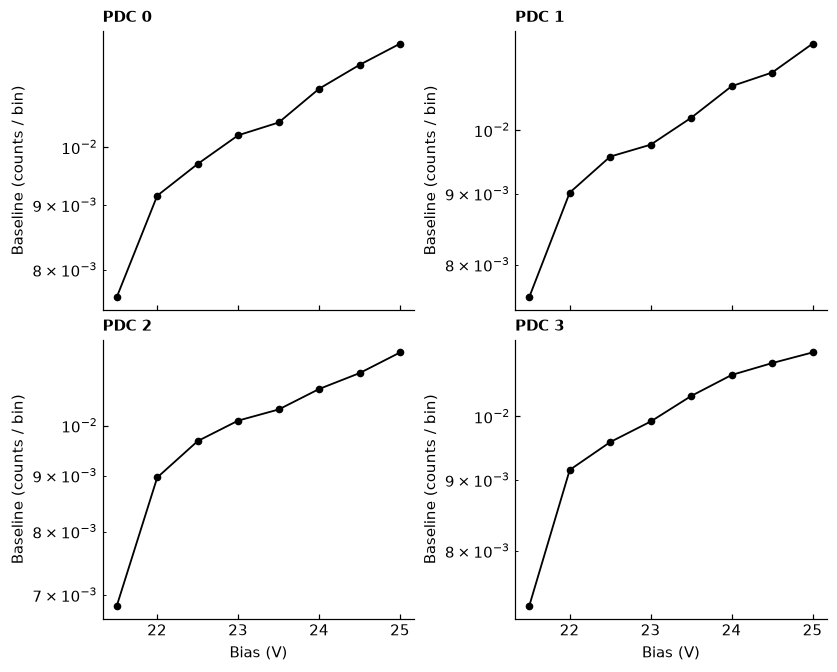

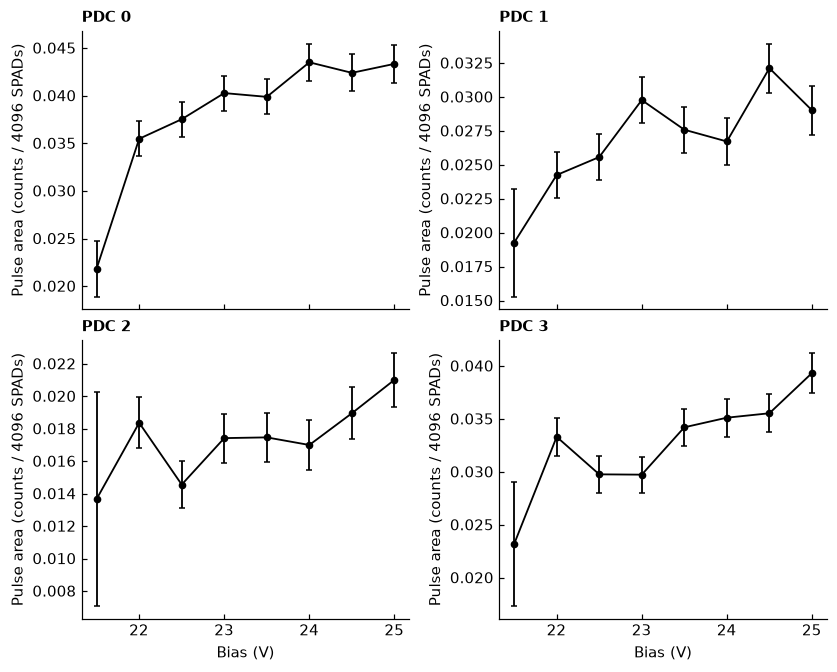

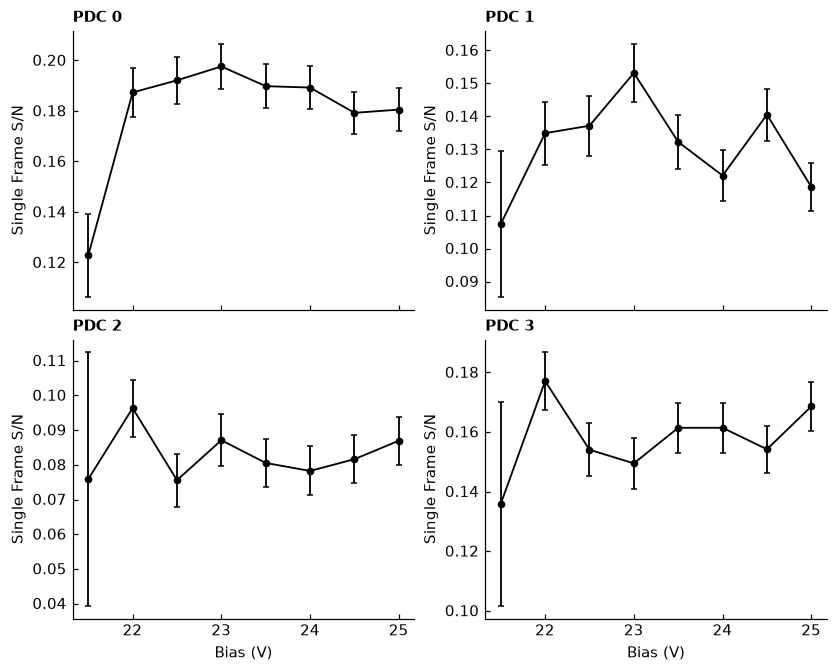

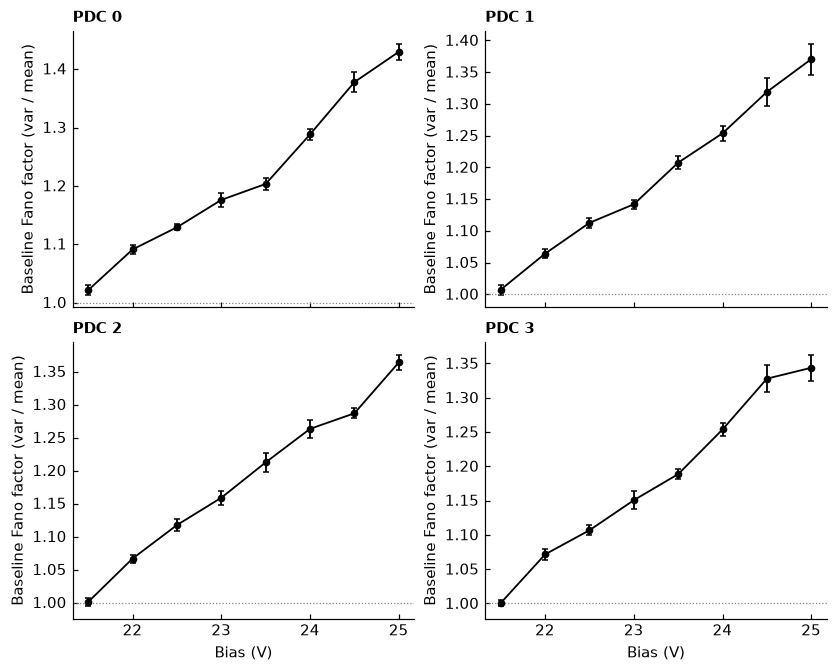

In [161]:
def plot_summary(col, err_col, ylabel, name, logy=False, ref_line=None):
    fig, axs = pdc_grid(len(PDC_LIST), sharey=False)
    for ax, pdc in zip(axs, PDC_LIST):
        df = SUMMARY[pdc]
        yerr = None if err_col is None else df[err_col].to_numpy()
        ax.errorbar(df["bias"], df[col], yerr=yerr, color="k", marker="o", ms=4, capsize=2)
        if logy:
            ax.set_yscale("log")
        if ref_line is not None:
            ax.axhline(ref_line, color="0.5", ls=":", lw=0.8)
    label_grid(axs, PDC_LIST, "Bias (V)", ylabel, sharey=False)
    save_fig(fig, name)
    plt.show()


plot_summary("baseline", None, "Baseline (counts / bin)", "dsum_baseline", logy=True)
plot_summary("pulse_area", "pulse_area_err", f"Pulse area (counts / {num_spads} SPADs)", "dsum_pulse_area")
plot_summary("snr", "snr_err", "Single Frame S/N", "dsum_snr")
plot_summary("fano", "fano_err", "Baseline Fano factor (var / mean)", "dsum_fano", ref_line=1)

## Waveforms

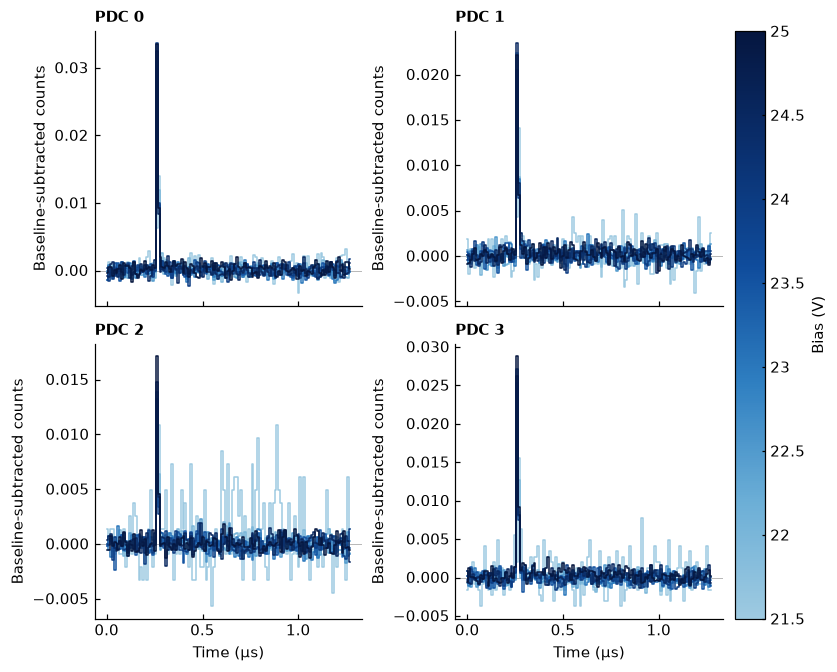

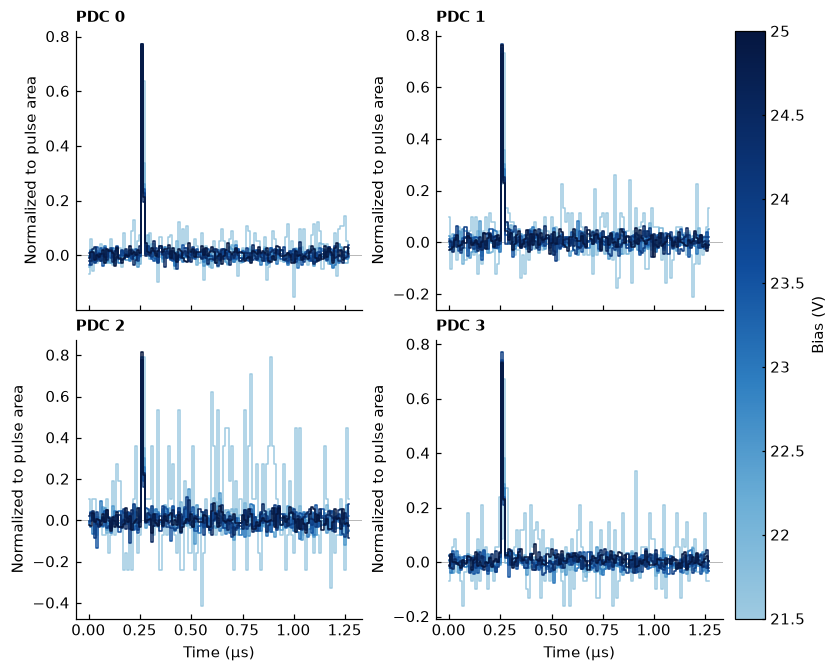

In [162]:
def plot_waveforms(normalized):
    levels = all_biases()
    fig, axs = pdc_grid(len(PDC_LIST), sharey=False)
    for ax, pdc in zip(axs, PDC_LIST):
        for v in biases_of(pdc):
            r = RES[(pdc, v)]
            t = np.arange(len(r["sig"])) * r["bin_ns"] / 1e3
            c = hue_color("bias", v, levels)
            if not normalized:
                ax.step(t, r["sig"], where="mid", color=c, lw=1)
                continue
            ref = r["pulse_area"] if NORMALIZE_BY == "area" else r["sig"][r["pw"]].max()
            if ref > 0:
                ax.step(t, r["sig"] / ref, where="mid", color=c, lw=1)
            else:
                warnings.warn(f"PDC{pdc} {v:g} V: non-positive {NORMALIZE_BY}, not drawn in normalized figure")
        ax.axhline(0, color="0.7", lw=0.6, zorder=0)
        if PLOT2_XLIM_US:
            ax.set_xlim(PLOT2_XLIM_US)
    ylabel = "Baseline-subtracted counts" if not normalized else ("Normalized to pulse area" if NORMALIZE_BY == "area" else "Normalized to peak")
    label_grid(axs, PDC_LIST, "Time (µs)", ylabel, sharey=False)
    add_hue_colorbar(fig, axs, "bias", levels)
    save_fig(fig, "dsum_waveforms_normalized" if normalized else "dsum_waveforms")
    plt.show()


plot_waveforms(normalized=False)
plot_waveforms(normalized=True)

## Power Spectral Densities

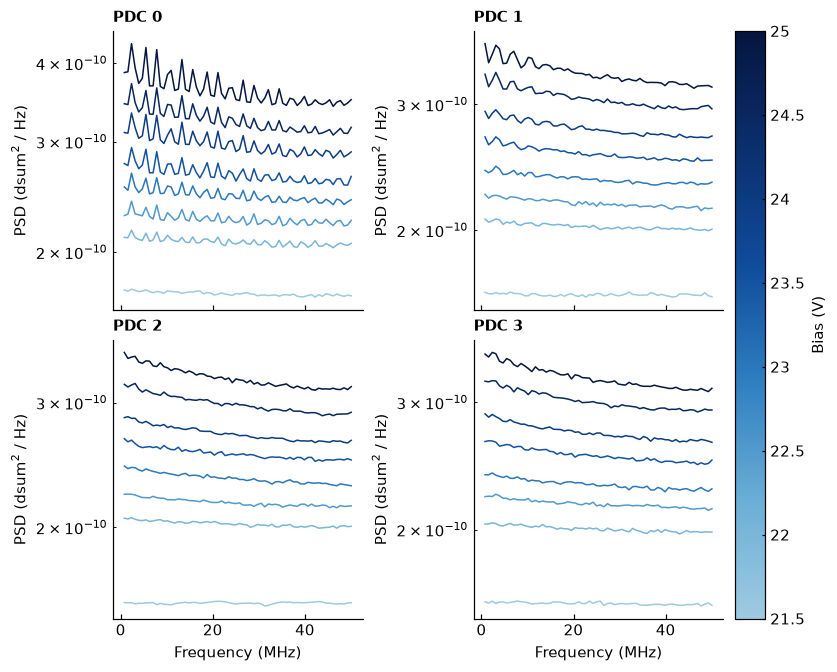

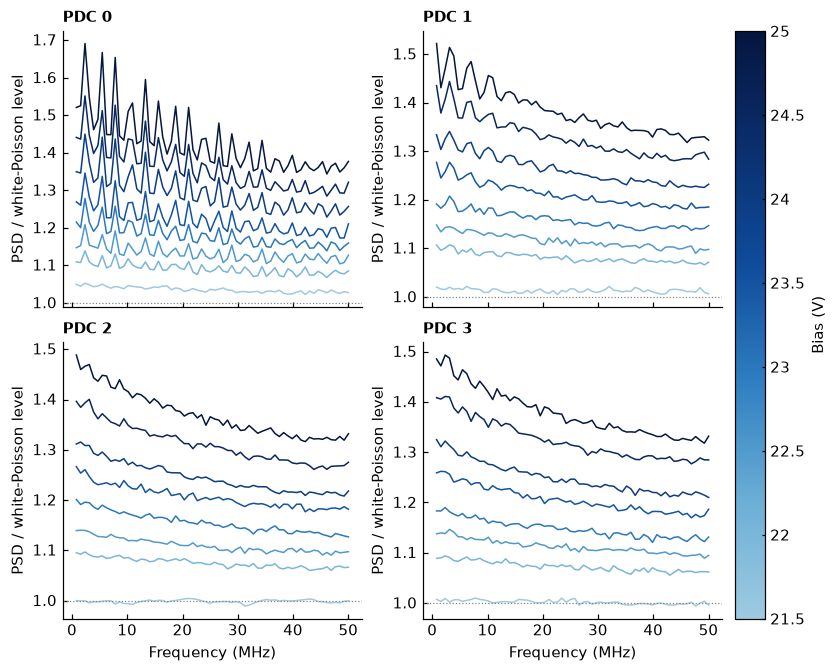

In [163]:
def plot_psd(normalized):
    levels = all_biases()
    fig, axs = pdc_grid(len(PDC_LIST), sharey=False)
    for ax, pdc in zip(axs, PDC_LIST):
        for v in biases_of(pdc):
            r = RES[(pdc, v)]
            f, p = r["freq_MHz"][1:], r["psd"][1:]
            poisson = 2 * r["bin_ns"] * 1e-9 * r["frame_mean"]
            ax.plot(f, p / poisson if normalized else p, color=hue_color("bias", v, levels), lw=1)
        if normalized:
            ax.axhline(1, color="0.5", ls=":", lw=0.8)
        else:
            ax.set_yscale("log")
    label_grid(axs, PDC_LIST, "Frequency (MHz)", "PSD / white-Poisson level" if normalized else "PSD (dsum$^2$ / Hz)", sharey=False)
    add_hue_colorbar(fig, axs, "bias", levels)
    save_fig(fig, "dsum_psd_normalized" if normalized else "dsum_psd")
    plt.show()


plot_psd(normalized=False)
plot_psd(normalized=True)